In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor()])
train_ds = datasets.FashionMNIST(root='/kaggle/working', train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root='/kaggle/working', train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.01MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.00MB/s]


In [2]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.CrossEntropyLoss()

def train_with_optimizer(opt_name, epochs=10):
    model = MLP().to(device)
    if opt_name == 'SGD':
        optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    elif opt_name == 'Adam':
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    elif opt_name == 'RMSProp':
        optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)

    val_accs = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                preds = model(x).argmax(dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)
        acc = correct / total
        val_accs.append(acc)
        print(f"{opt_name} Epoch {epoch+1}: val_acc={acc:.4f}")
    return val_accs

results = {}
for opt_name in ['SGD', 'Adam', 'RMSProp']:
    results[opt_name] = train_with_optimizer(opt_name)

SGD Epoch 1: val_acc=0.8096
SGD Epoch 2: val_acc=0.8331
SGD Epoch 3: val_acc=0.8434
SGD Epoch 4: val_acc=0.8522
SGD Epoch 5: val_acc=0.8574
SGD Epoch 6: val_acc=0.8495
SGD Epoch 7: val_acc=0.8669
SGD Epoch 8: val_acc=0.8715
SGD Epoch 9: val_acc=0.8756
SGD Epoch 10: val_acc=0.8733
Adam Epoch 1: val_acc=0.8401
Adam Epoch 2: val_acc=0.8430
Adam Epoch 3: val_acc=0.8664
Adam Epoch 4: val_acc=0.8717
Adam Epoch 5: val_acc=0.8764
Adam Epoch 6: val_acc=0.8787
Adam Epoch 7: val_acc=0.8742
Adam Epoch 8: val_acc=0.8824
Adam Epoch 9: val_acc=0.8788
Adam Epoch 10: val_acc=0.8864
RMSProp Epoch 1: val_acc=0.8202
RMSProp Epoch 2: val_acc=0.8506
RMSProp Epoch 3: val_acc=0.8525
RMSProp Epoch 4: val_acc=0.8742
RMSProp Epoch 5: val_acc=0.8700
RMSProp Epoch 6: val_acc=0.8762
RMSProp Epoch 7: val_acc=0.8727
RMSProp Epoch 8: val_acc=0.8784
RMSProp Epoch 9: val_acc=0.8659
RMSProp Epoch 10: val_acc=0.8830


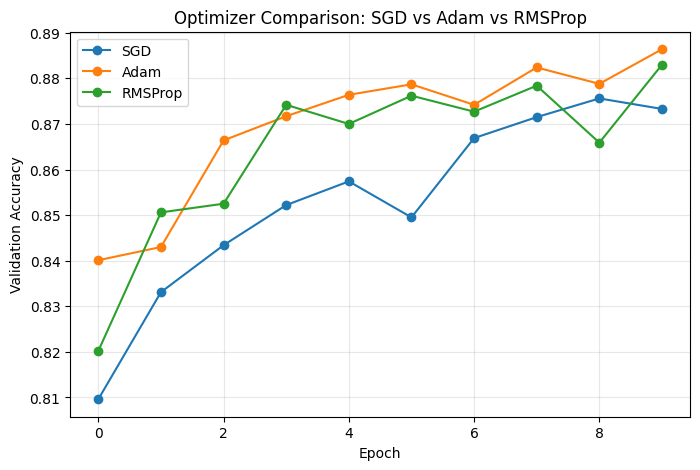

SGD: final acc = 0.8733
Adam: final acc = 0.8864
RMSProp: final acc = 0.8830


In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
for opt_name, accs in results.items():
    plt.plot(accs, label=opt_name, marker='o')
plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy')
plt.title('Optimizer Comparison: SGD vs Adam vs RMSProp')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('optimizer_comparison.png', dpi=150)
plt.show()

for opt_name, accs in results.items():
    print(f"{opt_name}: final acc = {accs[-1]:.4f}")

In [5]:
import json
json.dump(results, open('optimizer_results.json', 'w'))